# Чекпойнт 2 - EDA

**Детекция автоматизированного ввода текста по поведенческой телеметрии**  
ML-трек, руководитель - Дубровин Владислав

Исследуем естественный набор в KeyRecs и сравниваем его с синтетическим вводом в LSIA

## 1. KeyRecs

Данные обычного клавиатурного ввода: 99 участников, по две сессии. Меток ботов нет, поэтому KeyRecs нужен для анализа поведения людей и разброса между сессиями

In [1]:
from pathlib import Path
import random
import zipfile
import requests
from IPython.display import Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
sns.set_palette(['darkorange', 'dodgerblue'])
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (9, 4)
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_dir = root / 'data' / 'raw'
keyrecs_path = data_dir / 'keyrecs' / 'free-text.csv'
keyrecs_path.parent.mkdir(parents=True, exist_ok=True)
if not keyrecs_path.exists():
    url = 'https://zenodo.org/records/7886743/files/free-text.csv?download=1'
    response = requests.get(url, timeout=90)
    response.raise_for_status()
    keyrecs_path.write_bytes(response.content)

keyrecs = pd.read_csv(keyrecs_path, low_memory=False)
keyrecs.columns = keyrecs.columns.str.strip()
keyrecs = keyrecs.drop(columns='Unnamed: 9', errors='ignore')
time_cols = ['DU.key1.key1', 'DD.key1.key2', 'DU.key1.key2', 'UD.key1.key2', 'UU.key1.key2']
for col in time_cols:
    keyrecs[col] = pd.to_numeric(keyrecs[col], errors='coerce')
print('Строк:', len(keyrecs))
print('Столбцов:', len(keyrecs.columns))
print('Участников:', keyrecs['participant'].nunique())
print('Сессий:', keyrecs['session'].nunique())

Строк: 562583
Столбцов: 9
Участников: 99
Сессий: 2


In [2]:
display(keyrecs.head())

,participant,session,key1,key2,DU.key1.key1,DD.key1.key2,DU.key1.key2,UD.key1.key2,UU.key1.key2
0,p001,1,W,Shift,0.150,-0.796,0.166,-0.946,0.016
1,p001,1,Shift,e,0.962,1.148,1.255,0.186,0.293
2,p001,1,e,Space,0.107,0.172,0.252,0.065,0.145
3,p001,1,Space,b,0.080,0.200,0.280,0.120,0.200
4,p001,1,b,e,0.080,0.320,0.480,0.240,0.400


**Основные поля KeyRecs**

| Поле | Что означает | Зачем нужно |
|---|---|---|
| `participant` | Номер участника | Сравнение людей |
| `session` | Номер сессии | Проверка стабильности ввода |
| `key1`, `key2` | Первая и следующая клавиша | Контекст нажатий |
| `DU.key1.key1` | Время удержания первой клавиши | Продолжительность нажатия |
| `DD.key1.key2` | Интервал между нажатиями двух клавиш | Темп печати |
| `DU.key1.key2` | От нажатия первой до отпускания второй | Связь событий в паре |
| `UD.key1.key2` | От отпускания первой до нажатия второй | Пауза или перекрытие |
| `UU.key1.key2` | Интервал между отпусканиями | Дополнительный временной признак |

Основные для нашего проекта - удержание `DU.key1.key1`, интервал `DD.key1.key2` и пауза `UD.key1.key2`, остальные интервалы частично описывают те же события и могут быть сильно связаны друг с другом

In [3]:
display(keyrecs.describe(include='all').T.round(3))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
participant,562583,99,p049,6813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session,562583.0,NaN,NaN,NaN,1.50552,0.49997,1.0,1.0,2.0,2.0,2.0
key1,562583,132,Space,93871,NaN,NaN,NaN,NaN,NaN,NaN,NaN
key2,562385,145,Space,93870,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DU.key1.key1,562570.0,NaN,NaN,NaN,0.20365,2.944792,0.0,0.072,0.091,0.117,568.57
DD.key1.key2,562385.0,NaN,NaN,NaN,0.291818,5.968022,-568.083,0.12,0.174,0.272,1712.727
DU.key1.key2,562385.0,NaN,NaN,NaN,0.495465,5.49027,-7.935,0.216,0.272,0.379,1713.061
UD.key1.key2,562385.0,NaN,NaN,NaN,0.088476,5.479273,-568.162,0.019,0.081,0.173,1712.648
UU.key1.key2,562385.0,NaN,NaN,NaN,0.292115,4.635057,-10.782,0.118,0.176,0.272,1712.982


In [4]:
missing = pd.DataFrame({'Пропусков': keyrecs.isna().sum(), 'Доля, %': keyrecs.isna().mean() * 100})
display(missing.sort_values('Пропусков', ascending=False).round(3))

,Пропусков,"Доля, %"
key2,198,0.035
UU.key1.key2,198,0.035
UD.key1.key2,198,0.035
DU.key1.key2,198,0.035
DD.key1.key2,198,0.035
DU.key1.key1,13,0.002
participant,0,0.000
session,0,0.000
key1,0,0.000


198 пропусков в `key2` - ровно столько же, сколько сессий. Во всех случаях это последняя строка сессии, у которой нет следующей клавиши

In [5]:
last_rows = keyrecs.groupby(['participant', 'session']).tail(1)
print('Пар участник-сессия:', len(last_rows))
print('Пропусков key2:', keyrecs['key2'].isna().sum())
print('Последних строк без key2:', last_rows['key2'].isna().sum())

Пар участник-сессия: 198
Пропусков key2: 198
Последних строк без key2: 198


С `DU` другая история - 13 значений нельзя прочитать как числа. Ниже приведены исходные строки CSV и распределение ошибок по сессиям

In [6]:
raw_du = pd.read_csv(keyrecs_path, usecols=['DU.key1.key1'], dtype=str, keep_default_na=False)['DU.key1.key1']
missing_du = keyrecs['DU.key1.key1'].isna()
bad_du = raw_du[missing_du].value_counts()
print('Некорректных DU:', missing_du.sum())
display(keyrecs.loc[missing_du].groupby('session').size().rename('Пропусков').to_frame())
values_text = ', '.join(f'`{value!r}`: {count}' for value, count in bad_du.items())
display(Markdown(f'В исходном CSV вместо длительности нажатия встречаются {values_text}'))

Некорректных DU: 13


,Пропусков
session,
1,10
2,3


В исходном CSV вместо длительности нажатия встречаются `'Shift'`: 10, `'Backspace'`: 3

Эти 13 строк сохраняем - вместо некорректного `DU` остаётся `NaN`, остальные признаки не затрагиваем

Отрицательный `UD` возможен при перекрытии клавиш. Но отрицательный `DD` не должен возникать при обычном последовательном наборе, поэтому его стоит разобрать отдельно

In [7]:
quality = pd.DataFrame({'Отрицательных': (keyrecs[time_cols] < 0).sum(), 'Нулевых': (keyrecs[time_cols] == 0).sum(), 'Более 10 с по модулю': (keyrecs[time_cols].abs() > 10).sum()})
quality['Доля более 10 с, %'] = (keyrecs[time_cols].abs() > 10).sum().values / keyrecs[time_cols].notna().sum().values * 100
quality.index = ['Удержание', 'Между нажатиями', 'До отпускания второй', 'Пауза', 'Между отпусканиями']
display(quality.round(2))
dd_excluded = (keyrecs['DD.key1.key2'] < 0) | (keyrecs['DD.key1.key2'].abs() > 10)
dd_share = dd_excluded.sum() / keyrecs['DD.key1.key2'].notna().sum() * 100
print(f'Для корреляций исключено DD: {dd_excluded.sum()} ({dd_share:.2f}%)')

,Отрицательных,Нулевых,Более 10 с по модулю,"Доля более 10 с, %"
Удержание,0,5415,1327,0.24
Между нажатиями,8526,20,2801,0.50
До отпускания второй,16,0,1638,0.29
Пауза,97919,4618,1579,0.28
Между отпусканиями,17,632,297,0.05


Для корреляций исключено DD: 10100 (1.80%)


Отрицательные `DD` - распределение по сессиям и участникам

In [8]:
dd_negative = keyrecs['DD.key1.key2'] < 0
negative_dd = keyrecs[dd_negative]
print('Отрицательных DD:', dd_negative.sum(), 'из', len(keyrecs))
print('Доля:', round(dd_negative.mean() * 100, 2), '%')
print('Участников с такими записями:', negative_dd['participant'].nunique())
print('Минимальное DD, с:', keyrecs['DD.key1.key2'].min())
print('Максимальное DD, с:', keyrecs['DD.key1.key2'].max())

Отрицательных DD: 8526 из 562583
Доля: 1.52 %
Участников с такими записями: 99
Минимальное DD, с: -568.083
Максимальное DD, с: 1712.727


In [9]:
dd_sessions = keyrecs.assign(negative_dd=dd_negative).groupby('session')['negative_dd'].agg(['sum', 'count'])
dd_sessions['Доля, %'] = dd_sessions['sum'] / dd_sessions['count'] * 100
display(dd_sessions.rename(columns={'sum': 'Отрицательных', 'count': 'Всего'}) .round(2))

,Отрицательных,Всего,"Доля, %"
session,,,
1,4489,278186,1.61
2,4037,284397,1.42


In [10]:
dd_users = keyrecs.assign(negative_dd=dd_negative).groupby(['participant', 'session'])['negative_dd'].agg(['sum', 'count'])
dd_users['Доля, %'] = dd_users['sum'] / dd_users['count'] * 100
display(dd_users.sort_values('Доля, %', ascending=False).head(5).rename(columns={'sum': 'Отрицательных', 'count': 'Всего'}).round(2))
print('Сессий с отрицательными DD:', (dd_users['sum'] > 0).sum(), 'из', len(dd_users))

,,Отрицательных,Всего,"Доля, %"
participant,session,,,
p082,1,713,2915,24.46
p083,1,501,2644,18.95
p073,2,348,3655,9.52
p004,1,245,4700,5.21
p098,1,133,2838,4.69


Сессий с отрицательными DD: 198 из 198


Проверка соотношения `DD = DU + UD`

In [11]:
dd_error = (negative_dd['DD.key1.key2'] - negative_dd['DU.key1.key1'] - negative_dd['UD.key1.key2']).abs()
print('Отрицательных DD с совпадением временных интервалов:', round((dd_error < 0.005).mean() * 100, 2), '%')
print('DD от -0,2 до 0 с:', negative_dd['DD.key1.key2'].between(-0.2, 0).sum())
print('DD меньше -10 с:', (negative_dd['DD.key1.key2'] < -10).sum())
display(negative_dd['DD.key1.key2'].describe(percentiles=[0.25, 0.5, 0.75]).round(3).to_frame('Отрицательные DD'))

Отрицательных DD с совпадением временных интервалов: 100.0 %
DD от -0,2 до 0 с: 3816
DD меньше -10 с: 1227


,Отрицательные DD
count,8526.000
mean,-6.384
std,20.944
min,-568.083
25%,-3.295
50%,-0.249
75%,-0.083
max,-0.001


В KeyRecs оказалось 8526 отрицательных `DD` из 562583 записей (1,52%). В первой сессии их 4489 (1,61%), во второй - 4037 (1,42%). Из них 3816 близки к нулю, от -0,2 до 0 с, но ещё 1227 меньше -10 с - это уже сложно объяснить обычной печатью

Равенство `DD = DU + UD` выполняется для всех отрицательных `DD`, поэтому дело не в случайной ошибке одной колонки. Причину без исходных событий установить нельзя; для расчётов обычного темпа отрицательные `DD` не берём

**Что делаем с выбросами.** Порог 10 с по модулю выбран для анализа обычного темпа набора, а не для очистки всей выборки. Временные значения за этим порогом и отрицательные `DD` исключаются только из соответствующих расчётов корреляций и ограниченных распределений на графиках. Доля таких значений для каждого поля приведена в таблице выше; исходный `keyrecs` не меняется, строки остаются и доступны для дальнейшего анализа

Распределения интервалов - основной диапазон значений

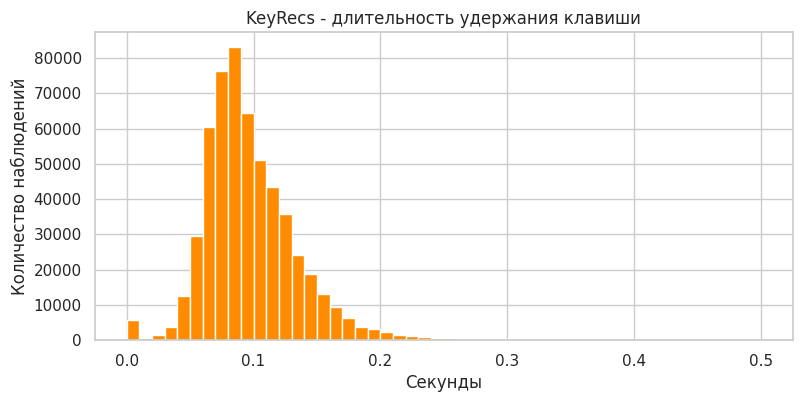

In [12]:
values = keyrecs.loc[keyrecs['DU.key1.key1'].between(0, 0.5), 'DU.key1.key1']
plt.hist(values, bins=50, color='darkorange')
plt.title('KeyRecs - длительность удержания клавиши')
plt.xlabel('Секунды')
plt.ylabel('Количество наблюдений')
plt.show()

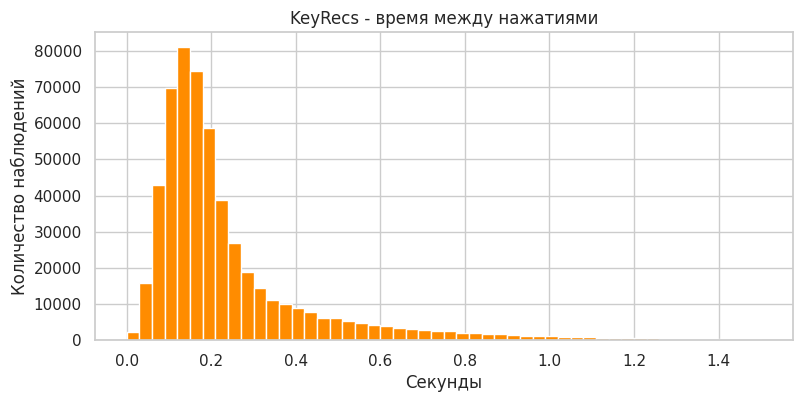

In [13]:
values = keyrecs.loc[keyrecs['DD.key1.key2'].between(0, 1.5), 'DD.key1.key2']
plt.hist(values, bins=50, color='darkorange')
plt.title('KeyRecs - время между нажатиями')
plt.xlabel('Секунды')
plt.ylabel('Количество наблюдений')
plt.show()

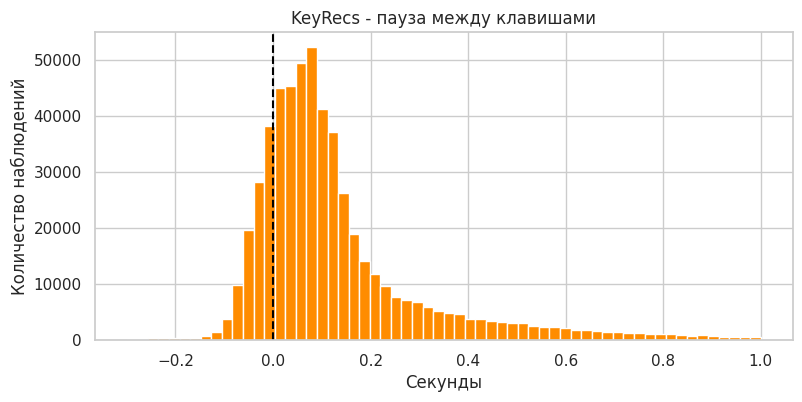

In [14]:
values = keyrecs.loc[keyrecs['UD.key1.key2'].between(-0.3, 1.0), 'UD.key1.key2']
plt.hist(values, bins=60, color='darkorange')
plt.axvline(0, color='black', linestyle='--')
plt.title('KeyRecs - пауза между клавишами')
plt.xlabel('Секунды')
plt.ylabel('Количество наблюдений')
plt.show()

Не все люди печатают одинаково

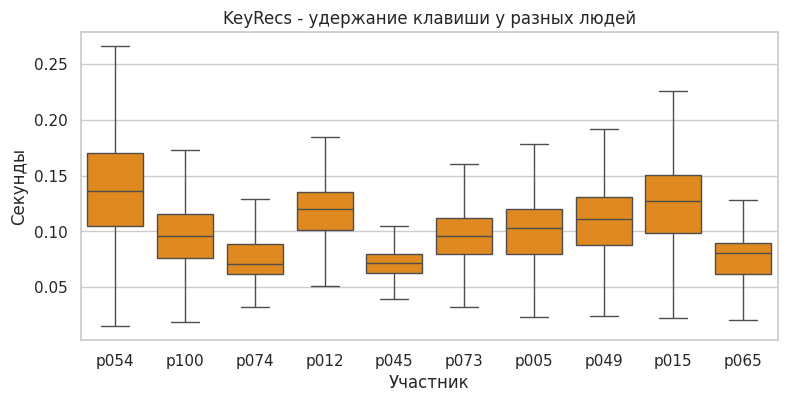

In [15]:
users = keyrecs['participant'].value_counts().head(10).index
user_data = keyrecs[keyrecs['participant'].isin(users) & keyrecs['DU.key1.key1'].between(0, 0.5)]
user_data = user_data.sample(n=min(12000, len(user_data)), random_state=42)
sns.boxplot(data=user_data, x='participant', y='DU.key1.key1', showfliers=False, color='darkorange')
plt.title('KeyRecs - удержание клавиши у разных людей')
plt.xlabel('Участник')
plt.ylabel('Секунды')
plt.show()

Насколько похожи две сессии одного человека?

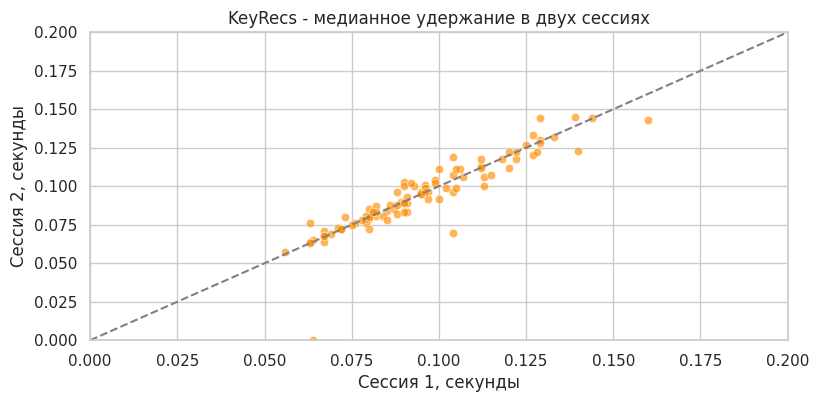

In [16]:
session_median = keyrecs.groupby(['participant', 'session'])['DU.key1.key1'].median().unstack()
sns.scatterplot(x=session_median[1], y=session_median[2], alpha=0.65, color='darkorange')
plt.plot([0, 0.2], [0, 0.2], color='gray', linestyle='--')
plt.xlim(0, 0.2)
plt.ylim(0, 0.2)
plt.title('KeyRecs - медианное удержание в двух сессиях')
plt.xlabel('Сессия 1, секунды')
plt.ylabel('Сессия 2, секунды')
plt.show()

Связь временных признаков

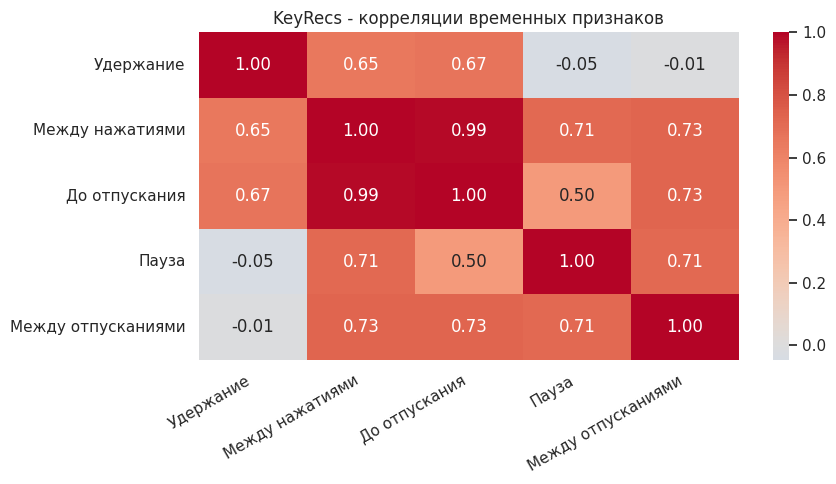

In [17]:
time_names = {'DU.key1.key1': 'Удержание', 'DD.key1.key2': 'Между нажатиями', 'DU.key1.key2': 'До отпускания', 'UD.key1.key2': 'Пауза', 'UU.key1.key2': 'Между отпусканиями'}
time_data = keyrecs[time_cols].mask(keyrecs[time_cols].abs() > 10).copy()
time_data.loc[time_data['DD.key1.key2'] < 0, 'DD.key1.key2'] = np.nan
corr = time_data.corr().rename(index=time_names, columns=time_names)
plt.figure(figsize=(9, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('KeyRecs - корреляции временных признаков')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Большая часть удержаний приходится на диапазон примерно 0,05-0,2 с, но разброс между участниками хорошо заметен. `DD`, `DU` и `UD` связаны формулой, поэтому высокая корреляция между ними ожидаема. Для модели нет смысла считать её независимым подтверждением

## 2. LSIA

Данные содержат человеческий ввод и его синтетические копии с теми же последовательностями клавиш. Один CSV - один образец

Архив `lsia_dataset.zip` можно скачать на [Mendeley Data](https://data.mendeley.com/datasets/mzm86rcxxd/2) через `Download All`. ZIP нужно положить в `data/raw/lsia_dataset.zip`; при первом запуске ноутбук распакует его в `data/raw/lsia/`

In [18]:
lsia_dir = data_dir / 'lsia'
lsia_zip = data_dir / 'lsia_dataset.zip'
lsia_dir.mkdir(parents=True, exist_ok=True)
if not any(lsia_dir.rglob('*.csv')):
    with zipfile.ZipFile(lsia_zip) as archive:
        archive.extractall(lsia_dir)
    for archive_path in lsia_dir.rglob('*.zip'):
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(archive_path.parent)

lsia_files = sorted(lsia_dir.rglob('*.csv'))
human_files = [p for p in lsia_files if p.stem.upper().endswith('-HUMAN')]
synthetic_files = [p for p in lsia_files if p.stem.endswith('Synthesizer')]
print('Всего CSV:', len(lsia_files))
print('Человеческих образцов:', len(human_files))
print('Синтетических образцов:', len(synthetic_files))

Всего CSV: 489216
Человеческих образцов: 18816
Синтетических образцов: 470400


In [19]:
example_path = human_files[0]
example = pd.read_csv(example_path)
print('Пример файла:', example_path.name)
display(example.head())

Пример файла: GAY-A10075453GKWMB0SRB9SQ-1-HUMAN.csv


,VK,HT,FT
0,16,210,-1
1,71,82,99
2,65,109,244
3,89,68,158
4,32,102,110


**Поля LSIA**

| Поле | Что означает | Использование |
|---|---|---|
| `VK` | Код клавиши | Backspace и состав последовательности |
| `HT` | Удержание клавиши, мс | Длительность нажатия |
| `FT` | Время между нажатиями, мс | Скорость и ритм |
| Имя файла | Источник, пользователь, текст, профиль, генератор | Парное сравнение человека и бота |

В `HT` и `FT` значение `-1` - не реальная задержка. По [описанию датасета](https://pmc.ncbi.nlm.nih.gov/articles/PMC10139888/) так помечены интервалы длиннее 1500 мс, а первый `FT` каждого образца тоже равен `-1`, потому что до первого нажатия нет предыдущего события

**Объём выборки**

Полный архив содержит 18816 человеческих и 470400 синтетических образцов. Для EDA берём по 400 человеческих образцов из GAY, GUN, LSIA и REVIEW, а из KM - все 79. К каждому оригиналу добавляем пять синтетических версий, по одной на метод. Всего получается 1679 человеческих и 8395 синтетических образцов

Используем один профиль `WithinSubjectAll`, чтобы сравнение методов было одинаковым. Выборка фиксируется через `random_state=42`, но не повторяет доли источников во всём архиве

In [20]:
rng = random.Random(42)
human_selected = []
for source in ['GAY', 'GUN', 'KM', 'LSIA', 'REVIEW']:
    source_files = [p for p in human_files if p.stem.startswith(source + '-')]
    human_selected.extend(rng.sample(source_files, min(400, len(source_files))))
selected_ids = {p.stem.rsplit('-', 1)[0] for p in human_selected}
selected = human_selected.copy()
for path in synthetic_files:
    parts = path.stem.split('-')
    if '-'.join(parts[:3]) in selected_ids and parts[-2] == 'WithinSubjectAll':
        selected.append(path)
assert len(selected) == len(human_selected) * 6
print('Человеческих образцов:', len(human_selected))
print('Синтетических образцов:', len(selected) - len(human_selected))

Человеческих образцов: 1679
Синтетических образцов: 8395


In [21]:
full_sources = pd.Series([p.stem.split('-')[0] for p in human_files]).value_counts()
selected_sources = pd.Series([p.stem.split('-')[0] for p in human_selected]).value_counts()
coverage = pd.DataFrame({'Всего человеческих': full_sources, 'Выбрано': selected_sources})
coverage['Доля, %'] = coverage['Выбрано'] / coverage['Всего человеческих'] * 100
display(coverage.sort_index().round(2))

,Всего человеческих,Выбрано,"Доля, %"
GAY,1594,400,25.09
GUN,1594,400,25.09
KM,79,79,100.00
LSIA,13597,400,2.94
REVIEW,1952,400,20.49


Статистики считаются по полным файлам; для гистограмм берём по 50 событий из каждого

In [22]:
rows = []
event_parts = []
for path in selected:
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.upper()
    df = df[['VK', 'HT', 'FT']].apply(pd.to_numeric, errors='coerce')
    parts = path.stem.split('-')
    label = 'human' if parts[-1].upper() == 'HUMAN' else 'synthetic'
    method = 'Human' if label == 'human' else parts[-1]
    profile = 'Human' if label == 'human' else parts[-2]
    df[['HT', 'FT']] = df[['HT', 'FT']].replace(-1, np.nan)
    rows.append({
        'source': parts[0], 'user': parts[1], 'sample_id': '-'.join(parts[:3]),
        'label': label, 'method': method, 'profile': profile, 'n_keys': len(df),
        'ht_median': df['HT'].median(), 'ht_std': df['HT'].std(),
        'ft_median': df['FT'].median(), 'ft_std': df['FT'].std(), 'ft_p90': df['FT'].quantile(0.9),
        'missing_ft_pct': df['FT'].isna().mean() * 100,
        'first_ft_missing': int(pd.isna(df['FT'].iloc[0])),
        'missing_ft_after_first': df['FT'].iloc[1:].isna().sum(), 'backspace_pct': df['VK'].eq(8).mean() * 100,
        'missing_vk': df['VK'].isna().sum(), 'missing_ht': df['HT'].isna().sum(), 'missing_ft': df['FT'].isna().sum(),
        'negative_ht': (df['HT'] < 0).sum(), 'negative_ft': (df['FT'] < 0).sum(),
        'zero_ht': df['HT'].eq(0).sum(), 'zero_ft': df['FT'].eq(0).sum(),
        'large_ht': (df['HT'] > 1500).sum(), 'large_ft': (df['FT'] > 1500).sum()
    })
    event_parts.append(df.sample(n=min(50, len(df)), random_state=42).assign(label=label))

samples = pd.DataFrame(rows)
events = pd.concat(event_parts, ignore_index=True)
samples['target'] = (samples['label'] == 'synthetic').astype(int)
method_names = {'Human': 'Человек', 'AverageSynthesizer': 'Среднее', 'UniformSynthesizer': 'Равномерный', 'GaussianSynthesizer': 'Нормальный', 'HistogramSynthesizer': 'Гистограмма', 'NonStationaryHistogramSynthesizer': 'Нестационарный'}
samples['method_name'] = samples['method'].replace(method_names)
print('Образцов:', len(samples))
print('Событий всего:', samples['n_keys'].sum())
print('Событий для графиков:', len(events))

Образцов: 10074
Событий всего: 8391618
Событий для графиков: 503700


In [23]:
display(samples.head())

,source,user,sample_id,label,method,profile,n_keys,ht_median,ht_std,ft_median,...,missing_ht,missing_ft,negative_ht,negative_ft,zero_ht,zero_ft,large_ht,large_ft,target,method_name
0,GAY,ACDGFPLZ9M929,GAY-ACDGFPLZ9M929-2,human,Human,Human,643,120.0,46.259981,152.0,...,0,1,0,0,0,0,0,0,0,Человек
1,GAY,A1MSLIBNIIGZHU,GAY-A1MSLIBNIIGZHU-1,human,Human,Human,1142,105.0,75.561364,169.0,...,0,7,0,0,0,0,0,0,0,Человек
2,GAY,A147QJNRYI5GM2,GAY-A147QJNRYI5GM2-4,human,Human,Human,989,111.0,75.380926,112.0,...,0,9,0,0,0,0,0,0,0,Человек
3,GAY,AVPKE76DJLWK6,GAY-AVPKE76DJLWK6-3,human,Human,Human,1071,96.0,190.103812,144.0,...,0,39,0,0,0,1,0,0,0,Человек
4,GAY,A2GZ0MWS800M6R,GAY-A2GZ0MWS800M6R-4,human,Human,Human,1116,109.0,136.096023,152.0,...,0,45,0,0,0,0,0,0,0,Человек


In [24]:
display(samples['method_name'].value_counts().rename('Образцов').to_frame())

,Образцов
method_name,
Человек,1679
Среднее,1679
Нормальный,1679
Гистограмма,1679
Нестационарный,1679
Равномерный,1679


Соотношение классов - 1:5

In [25]:
class_counts = samples['target'].value_counts().sort_index()
class_balance = pd.DataFrame({'Класс': ['Человек', 'Синтетика'], 'Образцов': [class_counts[0], class_counts[1]]})
class_balance['Доля, %'] = class_balance['Образцов'] / class_balance['Образцов'].sum() * 100
display(class_balance.round(2))
print(f'Accuracy при постоянном ответе «синтетика»: {class_counts[1] / class_counts.sum() * 100:.2f}%')

,Класс,Образцов,"Доля, %"
0,Человек,1679,16.67
1,Синтетика,8395,83.33


Accuracy при постоянном ответе «синтетика»: 83.33%


На синтетику приходится 5/6 всех образцов, поэтому простая accuracy здесь не показатель: модель, которая всегда отвечает бот, уже получит 83,33%. Для первых моделей будем использовать macro-F1, balanced accuracy и PR-AUC, а также проверять ошибки отдельно по каждому классу

Баланс по источникам

In [26]:
display(pd.crosstab(samples['source'], samples['label']))

label,human,synthetic
source,,
GAY,400,2000
GUN,400,2000
KM,79,395
LSIA,400,2000
REVIEW,400,2000


In [27]:
display(events[['VK', 'HT', 'FT']].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
VK,503700.0,68.23,29.62,0.0,65.0,72.0,80.0,233.0
HT,503700.0,117.42,97.22,0.0,80.0,102.0,129.0,1500.0
FT,501305.0,209.12,173.60,0.0,108.0,162.0,245.0,1500.0


Пропуски по всем событиям, а не только по точкам на графиках

In [28]:
total_events = samples['n_keys'].sum()
missing_lsia = pd.DataFrame({'Пропусков': [samples['missing_vk'].sum(), samples['missing_ht'].sum(), samples['missing_ft'].sum()]}, index=['VK', 'HT', 'FT'])
missing_lsia['Доля, %'] = missing_lsia['Пропусков'] / total_events * 100
display(missing_lsia.round(2))

,Пропусков,"Доля, %"
VK,0,0.00
HT,0,0.00
FT,41275,0.49


Первый `FT` в каждом образце отсутствует, поскольку предыдущей клавиши ещё не было. По описанию LSIA интервалы длиннее 1500 мс тоже заменялись на `-1`. Из-за этого число пропусков может зависеть не только от набора, но и от способа генерации

In [29]:
print('Образцов с пропущенным первым FT:', samples['first_ft_missing'].sum(), 'из', len(samples))
samples['missing_ft_extra_pct'] = samples['missing_ft_after_first'] / (samples['n_keys'] - 1) * 100
ft_by_method = samples.groupby('method_name')[['n_keys', 'missing_ft_after_first']].sum()
ft_by_method['Пропуски без первого FT, %'] = ft_by_method['missing_ft_after_first'] / (ft_by_method['n_keys'] - samples.groupby('method_name').size()) * 100
display(ft_by_method[['Пропуски без первого FT, %']].round(2))

Образцов с пропущенным первым FT: 10074 из 10074


,"Пропуски без первого FT, %"
method_name,
Гистограмма,0.00
Нестационарный,0.00
Нормальный,0.02
Равномерный,0.00
Среднее,0.00
Человек,2.21


Пропуски после первой клавиши - по источникам

In [30]:
ft_by_source = samples.groupby(['source', 'label'])[['n_keys', 'missing_ft_after_first']].sum()
ft_by_source['Пропуски без первого FT, %'] = ft_by_source['missing_ft_after_first'] / (ft_by_source['n_keys'] - samples.groupby(['source', 'label']).size()) * 100
display(ft_by_source[['Пропуски без первого FT, %']].round(2))

Пропуски без первого FT, %
source label                                
GAY    human                            1.89
       synthetic                        0.00
GUN    human                            1.84
       synthetic                        0.00
KM     human                            1.43
       synthetic                        0.00
LSIA   human                            4.02
       synthetic                        0.02
REVIEW human                            2.05
       synthetic                        0.00

In [31]:
ft_corr = samples[['missing_ft_pct', 'missing_ft_extra_pct', 'target']].corr()['target'].drop('target')
display(ft_corr.rename(index={'missing_ft_pct': 'Все пропуски FT', 'missing_ft_extra_pct': 'Без первого FT'}).round(3).to_frame('r с target'))
r_before = ft_corr['missing_ft_pct']
r_after = ft_corr['missing_ft_extra_pct']
display(Markdown(f'После исключения первого `FT` корреляция с `target`: **{r_after:+.3f}** (до исключения **{r_before:+.3f}**). Различие может отражать способ подготовки данных, а не только характер ввода'))

,r с target
Все пропуски FT,-0.710
Без первого FT,-0.714


После исключения первого `FT` корреляция с `target`: **-0.714** (до исключения **-0.710**). Различие может отражать способ подготовки данных, а не только характер ввода

Первый пропуск не объясняет сильную связь с классом: после его исключения корреляция остаётся около -0,714. Похоже, генераторы по-разному воспроизводят длинные паузы. Поэтому сравним baseline с долей пропусков `FT` и без неё - иначе получим слишком оптимистичную оценку

Аномальные и нулевые значения `HT` и `FT`

In [32]:
quality_lsia = pd.DataFrame({'Отрицательных': [samples['negative_ht'].sum(), samples['negative_ft'].sum()], 'Нулевых': [samples['zero_ht'].sum(), samples['zero_ft'].sum()], 'Более 1500 мс': [samples['large_ht'].sum(), samples['large_ft'].sum()]}, index=['HT', 'FT'])
display(quality_lsia)

,Отрицательных,Нулевых,Более 1500 мс
HT,0,56459,0
FT,0,88906,0


Нулевые значения могут быть следствием округления времени до миллисекунд или особенностей синтеза. Их частоты по классам важнее общего количества

In [33]:
zero_by_class = samples.groupby('label')[['n_keys', 'zero_ht', 'zero_ft']].sum()
zero_by_class['HT = 0, %'] = zero_by_class['zero_ht'] / zero_by_class['n_keys'] * 100
zero_by_class['FT = 0, %'] = zero_by_class['zero_ft'] / zero_by_class['n_keys'] * 100
display(zero_by_class[['HT = 0, %', 'FT = 0, %']].round(2))

,"HT = 0, %","FT = 0, %"
label,,
human,0.85,0.04
synthetic,0.64,1.26


In [34]:
samples['zero_ht_pct'] = samples['zero_ht'] / samples['n_keys'] * 100
samples['zero_ft_pct'] = samples['zero_ft'] / samples['n_keys'] * 100
zero_corr = samples[['zero_ht_pct', 'zero_ft_pct', 'target']].corr()['target'].drop('target')
display(zero_corr.rename(index={'zero_ht_pct': 'Нулевые HT', 'zero_ft_pct': 'Нулевые FT'}).round(3).to_frame('r с target'))

,r с target
Нулевые HT,-0.043
Нулевые FT,0.197


Доли нулей пока не используем как основные признаки - сначала разберёмся с точностью записи времени

In [35]:
features = ['n_keys', 'ht_median', 'ht_std', 'ft_median', 'ft_std', 'ft_p90', 'missing_ft_pct', 'backspace_pct']
display(samples[features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
n_keys,10074.0,833.00,440.88,250.00,615.00,726.00,917.00,3650.00
ht_median,10074.0,103.07,24.35,6.00,87.00,102.00,118.00,194.00
ht_std,10074.0,89.16,35.12,9.92,65.06,85.51,109.11,395.26
ft_median,10074.0,168.63,55.98,62.00,128.00,159.50,196.88,502.00
ft_std,10074.0,155.16,49.45,38.36,116.93,151.69,189.04,336.08
ft_p90,10074.0,379.09,136.99,123.00,275.53,353.75,458.90,1104.00
missing_ft_pct,10074.0,0.54,1.22,0.03,0.12,0.15,0.26,12.69
backspace_pct,10074.0,3.43,3.50,0.00,1.48,2.47,3.99,28.10


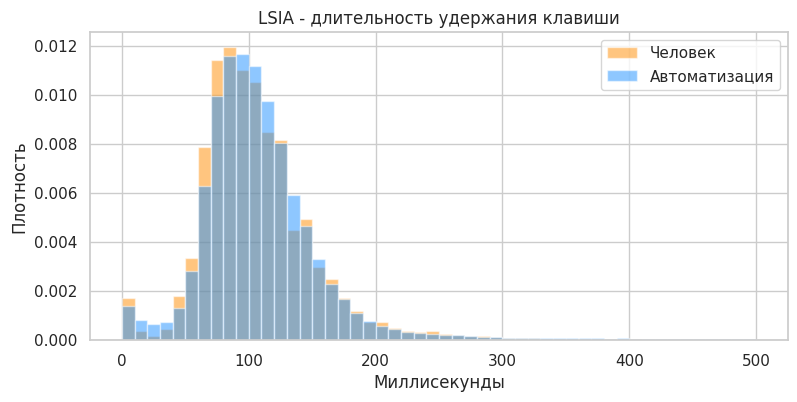

In [36]:
for label, title in [('human', 'Человек'), ('synthetic', 'Автоматизация')]:
    values = events.loc[(events['label'] == label) & events['HT'].between(0, 500), 'HT']
    plt.hist(values, bins=50, density=True, alpha=0.5, color='darkorange' if label == 'human' else 'dodgerblue', label=title)
plt.title('LSIA - длительность удержания клавиши')
plt.xlabel('Миллисекунды')
plt.ylabel('Плотность')
plt.legend()
plt.show()

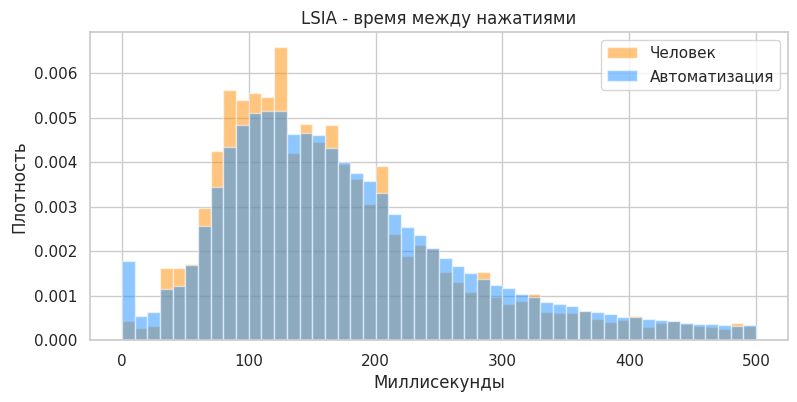

In [37]:
for label, title in [('human', 'Человек'), ('synthetic', 'Автоматизация')]:
    values = events.loc[(events['label'] == label) & events['FT'].between(0, 500), 'FT']
    plt.hist(values, bins=50, density=True, alpha=0.5, color='darkorange' if label == 'human' else 'dodgerblue', label=title)
plt.title('LSIA - время между нажатиями')
plt.xlabel('Миллисекунды')
plt.ylabel('Плотность')
plt.legend()
plt.show()

In [38]:
class_stats = samples.groupby('label')[features].median()
display(class_stats.round(2))
print('FT медиана: человек:', round(class_stats.loc['human', 'ft_median'], 2), 'мс, синтетика:', round(class_stats.loc['synthetic', 'ft_median'], 2), 'мс')
print('FT разброс: человек:', round(class_stats.loc['human', 'ft_std'], 2), 'мс, синтетика:', round(class_stats.loc['synthetic', 'ft_std'], 2), 'мс')

,n_keys,ht_median,ht_std,ft_median,ft_std,ft_p90,missing_ft_pct,backspace_pct
label,,,,,,,,
human,726.0,101.0,88.81,152.0,182.17,368.0,2.05,2.47
synthetic,726.0,103.0,84.95,161.0,145.44,350.8,0.14,2.47


FT медиана: человек: 152.0 мс, синтетика: 161.0 мс
FT разброс: человек: 182.17 мс, синтетика: 145.44 мс


Медиана `FT` у человека - 152 мс, у синтетики - 161 мс. Разница небольшая, а графики сильно пересекаются. По одному интервалу автоматизацию вряд ли получится уверенно определить, важнее характеристики всего образца

In [39]:
source_stats = samples.groupby(['source', 'label'])[['ft_median', 'ft_std', 'ft_p90', 'missing_ft_pct']].median()
display(source_stats.round(2))
source_std = source_stats['ft_std'].unstack()
print('Источников с меньшим медианным разбросом FT у синтетики:', (source_std['synthetic'] < source_std['human']).sum(), 'из', len(source_std))

ft_median  ft_std  ft_p90  missing_ft_pct
source label                                               
GAY    human          136.0  169.30  328.30            1.41
       synthetic      144.0  128.63  308.35            0.13
GUN    human          141.0  170.59  332.60            1.51
       synthetic      147.0  131.03  314.80            0.13
KM     human          167.5  183.00  410.00            0.91
       synthetic      179.5  145.97  373.20            0.06
LSIA   human          187.0  216.08  502.55            3.79
       synthetic      200.0  192.08  485.50            0.25
REVIEW human          143.0  172.75  336.00            1.66
       synthetic      150.0  134.14  318.80            0.14

Источников с меньшим медианным разбросом FT у синтетики: 5 из 5


Разница в разбросе `FT` есть во всех пяти источниках, но не одинаковая. Например, в GAY медиана падает с 169,30 до 128,63 мс, а в LSIA - с 216,08 до 192,08 мс. Значит, результаты общей выборки лучше проверять отдельно по источникам

In [40]:
display(samples.groupby('method_name')[['ht_median', 'ht_std', 'ft_median', 'ft_std', 'ft_p90']].median().round(2))

,ht_median,ht_std,ft_median,ft_std,ft_p90
method_name,,,,,
Гистограмма,98.0,96.02,144.0,165.12,343.0
Нестационарный,109.0,96.39,148.0,164.91,346.2
Нормальный,101.0,97.10,162.5,169.23,417.0
Равномерный,102.0,73.03,171.0,113.43,331.6
Среднее,103.0,69.77,175.0,105.35,311.0
Человек,101.0,88.81,152.0,182.17,368.0


Разброс `FT` у разных генераторов

/var/folders/vq/0yqvd11s7kv3blkldb1q1_9w0000gn/T/ipykernel_54871/1127968546.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=samples, x='method_name', y='ft_std', showfliers=False, order=['Человек', 'Среднее', 'Равномерный', 'Нормальный', 'Гистограмма', 'Нестационарный'], palette=['darkorange'] + ['dodgerblue'] * 5)


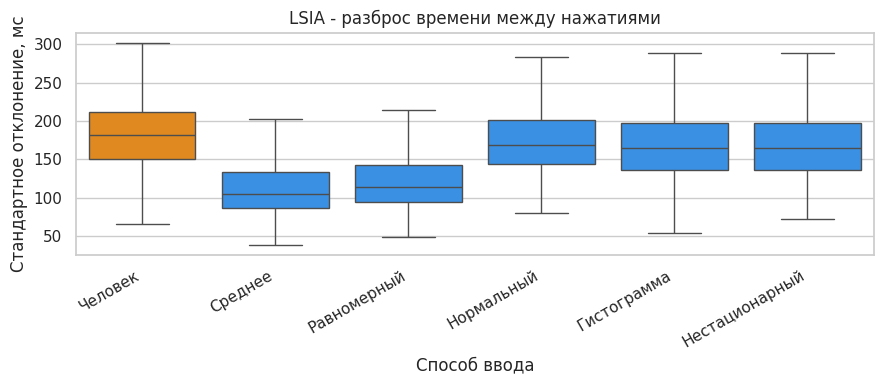

In [41]:
sns.boxplot(data=samples, x='method_name', y='ft_std', showfliers=False, order=['Человек', 'Среднее', 'Равномерный', 'Нормальный', 'Гистограмма', 'Нестационарный'], palette=['darkorange'] + ['dodgerblue'] * 5)
plt.title('LSIA - разброс времени между нажатиями')
plt.xlabel('Способ ввода')
plt.ylabel('Стандартное отклонение, мс')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Таргет - 0 человек, 1 синтетика

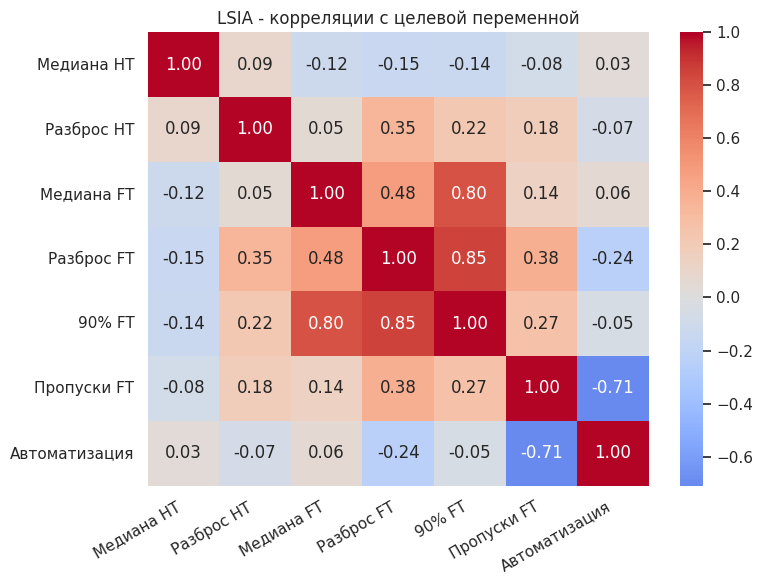

In [42]:
names = {'ht_median': 'Медиана HT', 'ht_std': 'Разброс HT', 'ft_median': 'Медиана FT', 'ft_std': 'Разброс FT', 'ft_p90': '90% FT', 'missing_ft_pct': 'Пропуски FT', 'target': 'Автоматизация'}
corr = samples[list(names)].corr().rename(index=names, columns=names)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('LSIA - корреляции с целевой переменной')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
corr_target = samples[features + ['target']].corr()['target'].drop('target')
top_corr = pd.DataFrame({'r': corr_target, 'Модуль r': corr_target.abs()}).sort_values('Модуль r', ascending=False).head(5)
feature_names = {'n_keys': 'Количество клавиш', 'ht_median': 'Медиана HT', 'ht_std': 'Разброс HT', 'ft_median': 'Медиана FT', 'ft_std': 'Разброс FT', 'ft_p90': '90-й процентиль FT', 'missing_ft_pct': 'Пропуски FT', 'backspace_pct': 'Доля Backspace'}
display(top_corr[['r']].rename(index=feature_names).round(3))

,r
Пропуски FT,-0.710
Разброс FT,-0.241
Разброс HT,-0.067
Медиана FT,0.062
90-й процентиль FT,-0.051


Самая сильная корреляция с `target` - у доли пропусков `FT` (`r = -0,710`). После исключения обязательного первого события она даже немного усиливается до `r = -0,714`. Для сравнения, корреляция разброса `FT` всего `-0,241`. Скорее всего, часть сигнала связана с подготовкой синтетических данных, а не с самим поведением

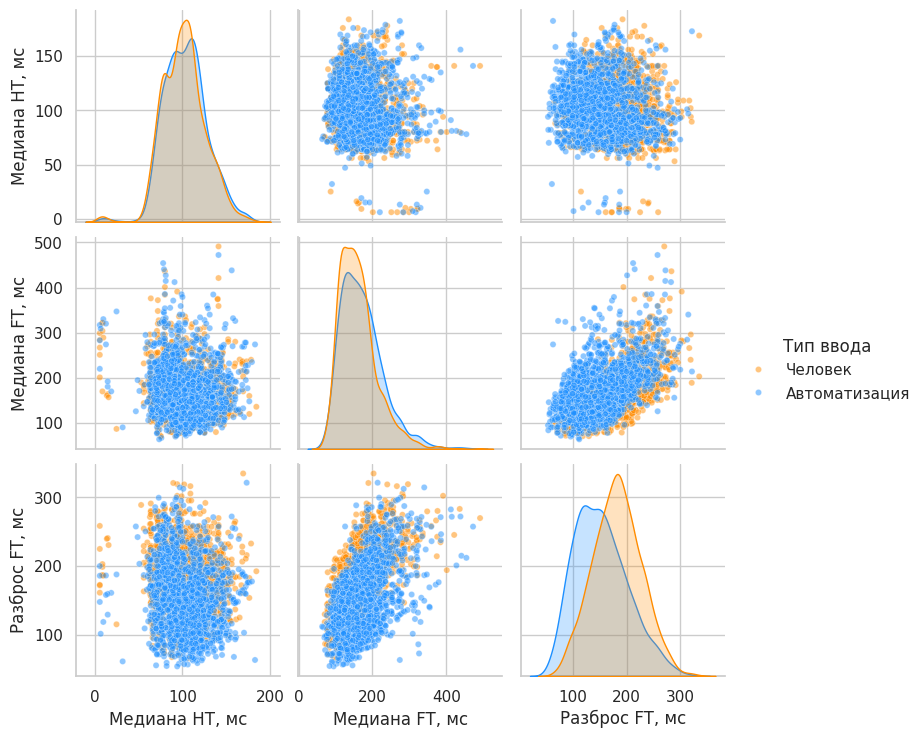

In [44]:
human_plot = samples[samples['label'] == 'human']
synthetic_plot = samples[samples['label'] == 'synthetic'].sample(n=len(human_plot), random_state=42)
plot_data = pd.concat([human_plot, synthetic_plot])[['ht_median', 'ft_median', 'ft_std', 'label']].copy()
plot_data = plot_data.rename(columns={'ht_median': 'Медиана HT, мс', 'ft_median': 'Медиана FT, мс', 'ft_std': 'Разброс FT, мс', 'label': 'Тип ввода'})
plot_data['Тип ввода'] = plot_data['Тип ввода'].replace({'human': 'Человек', 'synthetic': 'Автоматизация'})
sns.pairplot(plot_data, hue='Тип ввода', palette={'Человек': 'darkorange', 'Автоматизация': 'dodgerblue'}, plot_kws={'alpha': 0.5, 's': 20})
plt.show()

In [45]:
human_std = samples[samples['label'] == 'human'][['sample_id', 'ft_std']].rename(columns={'ft_std': 'human_ft_std'})
paired = samples[samples['label'] == 'synthetic'].merge(human_std, on='sample_id')
paired['ft_std_diff'] = paired['ft_std'] - paired['human_ft_std']
display(paired.groupby('method_name')['ft_std_diff'].agg(['count', 'median', 'mean']).round(2))

,count,median,mean
method_name,,,
Гистограмма,1679,-13.27,-12.30
Нестационарный,1679,-13.26,-12.35
Нормальный,1679,-7.58,-6.70
Равномерный,1679,-62.72,-60.54
Среднее,1679,-70.25,-68.30


In [46]:
source_method_diff = paired.groupby(['source', 'method_name'])['ft_std_diff'].median().unstack()
display(source_method_diff.round(2))
print('Пар, где синтетика ровнее человека:', (paired['ft_std_diff'] < 0).sum(), 'из', len(paired))

method_name,Гистограмма,Нестационарный,Нормальный,Равномерный,Среднее
source,,,,,
GAY,-14.93,-13.96,-7.80,-63.55,-71.47
GUN,-17.46,-15.84,-9.75,-66.01,-73.96
KM,-9.18,-11.12,-5.18,-59.73,-69.67
LSIA,-5.07,-6.96,-3.35,-54.15,-59.78
REVIEW,-15.18,-16.10,-11.01,-66.16,-74.43


Пар, где синтетика ровнее человека: 6738 из 8395


Отрицательная разница означает, что бот печатает ровнее исходного человека

Из 8395 пар в 6738 синтетический образец имел меньший разброс `FT`, чем человеческий. Но генераторы очень разные: у метода Среднее медианная разница -70,25 мс, у Нормального всего -7,58 мс. Одного `ft_std` для сложных ботов будет мало

**Разбиение train/test**

Пять синтетических копий и оригинал имеют общий `sample_id`, поэтому обычное случайное деление строк приведёт к утечке. Разделяем пользователей примерно 80/20 отдельно в каждом источнике. Все тексты одного пользователя и их копии остаются в одной части

In [47]:
samples['user_id'] = samples['source'] + '-' + samples['user']
train_users = set()
for source, group in samples.groupby('source'):
    users = group['user_id'].drop_duplicates().sample(frac=1, random_state=42)
    train_users.update(users.iloc[:int(len(users) * 0.8)])
samples['split'] = np.where(samples['user_id'].isin(train_users), 'train', 'test')
display(pd.crosstab([samples['source'], samples['split']], samples['label']))
print('sample_id в обеих частях:', (samples.groupby('sample_id')['split'].nunique() > 1).sum())
print('user_id в обеих частях:', (samples.groupby('user_id')['split'].nunique() > 1).sum())

label         human  synthetic
source split                  
GAY    test      77        385
       train    323       1615
GUN    test      78        390
       train    322       1610
KM     test      16         80
       train     63        315
LSIA   test      76        380
       train    324       1620
REVIEW test      78        390
       train    322       1610

sample_id в обеих частях: 0
user_id в обеих частях: 0


## 3. Выводы

**KeyRecs.** Из 562583 записей 8526 (1,52%) имеют отрицательный `DD`, причём они встречаются во всех 198 сессиях. Во второй сессии их доля немного ниже - 1,42% против 1,61% в первой. Неправдоподобные интервалы не используем при расчёте обычного темпа, но сами строки не удаляем. Ещё 13 значений `DU` записаны текстом: для расчётов этого признака они остаются `NaN`

**LSIA.** В выборке 1679 человеческих и 8395 синтетических образцов медианный разброс `FT` составляет 182,17 и 145,44 мс соответственно. В GAY разница заметнее, чем в LSIA, а у разных генераторов она ещё сильнее отличается: -70,25 мс для метода Среднее против -7,58 мс для Нормального. Поэтому начнём с медиан и разброса `HT`/`FT`, но дальше понадобятся признаки последовательности

**Пропуски `FT`.** Корреляция `missing_ft_pct` с классом равна `-0,710`, а после исключения обязательного первого события - **-0,714**. Связь почти не изменилась, значит, дело не только в первом `FT`. Возможна техническая особенность генераторов, особенно при обработке пауз длиннее 1500 мс. В baseline обязательно сравним качество с этим признаком и без него

**Дальше.** Классы несбалансированы 1:5, так что одной accuracy недостаточно - используем macro-F1, balanced accuracy и PR-AUC. Train/test делим по пользователям внутри источников, не разделяя один `sample_id` между частями. Все эти наблюдения пока относятся к выбранной части LSIA и профилю `WithinSubjectAll`; перенос на другие профили и новых ботов предстоит проверять отдельно

Датасеты: [KeyRecs](https://zenodo.org/records/7886743), [LSIA](https://data.mendeley.com/datasets/mzm86rcxxd/2)